<a href="https://colab.research.google.com/github/EmiiFernandez/actividades_data_sciente_ypf/blob/main/notebook/C17_Notebook-21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

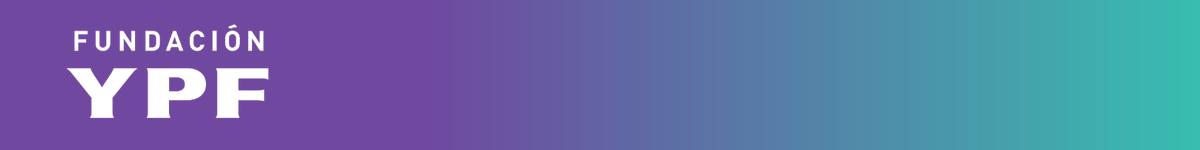

# Fundación YPF - Data Science

## Notebook 21 C17: Clasificación e interpretación local de variables (LIME y SHAP)

### Índice

* **Parte 0.** Repaso y definición del problema: clasificar el estado de un país (life expectancy).
* **Parte 1.** Exploración rápida de los datos.
* **Parte 2.** La partición: por qué una partición aleatoria no alcanza.
* **Parte 3.** Modelos, validación cruzada y selección.
* **Parte 4.** Explicabilidad global: coeficientes, importancia por permutación y SHAP.
* **Parte 5.** Explicabilidad local: LIME y SHAP sobre observaciones individuales.
* **Parte 6.** Ejercicio para las salas de Zoom (venta de autos).
* **Anexo.** Soluciones sugeridas de la Parte 6.

### Cómo se usa esta notebook

La clase se recorre en sala general de la Parte 0 a la Parte 5, con el dataset de expectativa de vida. La Parte 6 se trabaja en las salas de Zoom con un dataset distinto (venta de autos) y el Anexo trae las soluciones sugeridas para la puesta en común.

Esta notebook junta lo que vimos en el módulo V en un problema de clasificación de punta a punta:

* Los modelos de las clases 12 y 13 (regresión logística, árboles, Random Forest).
* Las métricas de la clase 15: F1, curva ROC y AUC, y el piso de referencia.
* La validación cruzada y la optimización de hiperparámetros de la clase 16, incluido `GroupKFold`.

Y le suma lo nuevo de hoy: **explicar** las predicciones de un modelo de caja negra con importancia por permutación, **SHAP** y **LIME**.

**Datasets que necesita:** `life_expectancy_data.csv` y `venta_autos.csv`. Tienen que estar en `/content/` si se trabaja en Colab, o en la misma carpeta que la notebook si se trabaja de forma local.

## Parte 0. Repaso y definición del problema

### Instalación de las librerías de explicabilidad

`shap` y `lime` no vienen instaladas en Colab. Este bloque las instala solamente si hacen falta.

In [ ]:
try:
    import shap
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:
    %pip install -q shap lime
    import shap
    from lime.lime_tabular import LimeTabularExplainer

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
                             f1_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, GroupShuffleSplit, StratifiedGroupKFold,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (8, 4)
SEMILLA = 42

In [ ]:
def leer_csv(nombre):
    """Lee un CSV desde /content/ (Colab) y, si no existe, desde el directorio local."""
    try:
        return pd.read_csv("/content/" + nombre)
    except FileNotFoundError:
        return pd.read_csv(nombre)


df = leer_csv("life_expectancy_data.csv")
df.columns = df.columns.str.strip().str.replace(r"\s+", " ", regex=True)
print(df.shape)
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'life_expectancy_data.csv'

### El problema

Cada fila es un país en un año. La columna `Status` dice si el país es `Developed` o `Developing`. Vamos a construir un **clasificador** que, a partir de indicadores de salud, educación y economía, prediga ese estado. El objetivo no es el modelo en sí: es después poder preguntarle **por qué** decide lo que decide.

Definimos `y = 1` para los países desarrollados, que es la clase minoritaria y la que nos interesa detectar. Sacamos de `X` las columnas `Status` (es la variable objetivo), `Country` (un identificador) y `Year`. Guardamos `Country` aparte porque lo vamos a necesitar en la Parte 2.

In [ ]:
y = (df["Status"] == "Developed").astype(int)
paises = df["Country"]
X = df.drop(columns=["Status", "Country", "Year"])

print("Proporción de países desarrollados:", round(y.mean(), 3))
print("Exactitud del piso (siempre 'Developing'):", round(1 - y.mean(), 3))
print("Países distintos:", paises.nunique(), "| Filas:", len(df))
print("Países que cambian de Status entre años:", int((df.groupby("Country")["Status"].nunique() > 1).sum()))

Dos cosas para tener presentes desde ahora:

* La clase de interés es minoritaria (alrededor del 17%), así que la exactitud del piso es alta y vamos a mirar **F1 y AUC**, como en la clase 15.
* **Ningún país cambia de `Status` entre años.** Cada país aparece muchas veces (una por año) siempre con la misma etiqueta. Esto tiene consecuencias importantes para la partición, y las vemos en la Parte 2.

## Parte 1. Exploración rápida

Antes de modelar miramos los faltantes y qué variables parecen separar a las dos clases.

In [ ]:
faltantes = X.isna().mean().sort_values(ascending=False)
print("Columnas con faltantes:", int((faltantes > 0).sum()), "de", X.shape[1])
faltantes.head(6).round(3)

In [ ]:
correlaciones = X.corrwith(y).sort_values()
extremos = pd.concat([correlaciones.head(4), correlaciones.tail(4)])

extremos.plot(kind="barh", color=["#753BAE" if v < 0 else "#38BEB0" for v in extremos])
plt.axvline(0, color="gray", linewidth=1)
plt.xlabel("Correlación con ser un país desarrollado")
plt.title("Variables más asociadas con el Status")
plt.tight_layout()
plt.show()

In [ ]:
variables = ["Schooling", "Income composition of resources", "Adult Mortality", "Life expectancy"]
fig, ejes = plt.subplots(1, 4, figsize=(13, 3.5))
for eje, variable in zip(ejes, variables):
    df.boxplot(column=variable, by="Status", ax=eje, grid=False)
    eje.set_title(variable, fontsize=10)
    eje.set_xlabel("")
fig.suptitle("")
plt.tight_layout()
plt.show()

Los países desarrollados tienen más años de escolaridad, mayor expectativa de vida y menor mortalidad adulta. El problema tiene señal fuerte. Guardamos esas variables en la cabeza: en la Parte 4 vamos a ver si el modelo entrenado las usa.

## Parte 2. La partición: por qué una partición aleatoria no alcanza

En la clase 16 vimos con `GroupKFold` que, cuando hay filas que pertenecen al mismo grupo, una partición al azar deja filas del mismo grupo en entrenamiento y en test. Acá el grupo es el **país**, y como su `Status` nunca cambia, el modelo puede "reconocer" al país por sus indicadores (que cambian poco de un año al siguiente) y acertar la etiqueta sin haber aprendido nada general.

Lo comprobamos entrenando el mismo Random Forest con dos particiones distintas.

In [ ]:
imputador = SimpleImputer(strategy="median").set_output(transform="pandas")

def armar_rf(**parametros):
    return Pipeline([("imputador", imputador), ("clf", RandomForestClassifier(random_state=SEMILLA, **parametros))])

# Partición aleatoria (la que veníamos usando)
X_tr_a, X_te_a, y_tr_a, y_te_a = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)
f1_aleatoria = f1_score(y_te_a, armar_rf(n_estimators=200).fit(X_tr_a, y_tr_a).predict(X_te_a))

# Partición por país: ningún país está a la vez en entrenamiento y en test
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
idx_train, idx_test = next(gss.split(X, y, groups=paises))
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
paises_train, paises_test = paises.iloc[idx_train], paises.iloc[idx_test]
f1_por_pais = f1_score(y_test, armar_rf(n_estimators=200).fit(X_train, y_train).predict(X_test))

print(f"F1 con partición aleatoria: {f1_aleatoria:.2f}")
print(f"F1 con partición por país:  {f1_por_pais:.2f}")
print("Países en común entre train y test:", len(set(paises_train) & set(paises_test)))

**Para discutir:** el modelo y los datos son los mismos, y el F1 cae muchísimo. Con la partición aleatoria estábamos midiendo qué tan bien el modelo **recuerda países ya vistos**; con la partición por país medimos qué tan bien **generaliza a países nuevos**, que es lo que en la práctica nos interesa. La estimación honesta es la segunda.

Desde acá trabajamos siempre con la partición por país. Guardamos los datos ya separados en `X_train`, `X_test`, `y_train` y `y_test`.

Una advertencia: el test tiene pocos países desarrollados, así que su resultado es ruidoso, como aprendimos en la clase 16.

In [ ]:
print("Filas de train:", len(X_train), "| test:", len(X_test))
print("Países de train:", paises_train.nunique(), "| test:", paises_test.nunique())
print("Países desarrollados en test:", paises_test[y_test == 1].nunique())

## Parte 3. Modelos, validación cruzada y selección

Comparamos cuatro modelos con validación cruzada **sobre el entrenamiento**. Como los grupos importan también acá, usamos `StratifiedGroupKFold`: conserva la proporción de clases en cada fold **y** mantiene todas las filas de un país del mismo lado.

Los modelos que dependen de la escala (la regresión logística) llevan un `StandardScaler`. Los basados en árboles no lo necesitan, y así después podemos explicarlos en las unidades originales de cada variable.

In [ ]:
def armar_lr():
    return Pipeline([("imputador", imputador), ("escalador", StandardScaler()),
                     ("clf", LogisticRegression(max_iter=1000))])

modelos = {
    "Piso (Dummy)": Pipeline([("imputador", imputador), ("clf", DummyClassifier(strategy="prior"))]),
    "Regresión logística": armar_lr(),
    "Árbol (profundidad 4)": Pipeline([("imputador", imputador),
                                       ("clf", DecisionTreeClassifier(max_depth=4, random_state=SEMILLA))]),
    "Random Forest": armar_rf(n_estimators=100),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

resultados = {}
for nombre, modelo in modelos.items():
    resultados[nombre] = cross_validate(modelo, X_train, y_train, cv=cv, groups=paises_train,
                                        scoring=["accuracy", "f1", "roc_auc"])

pd.DataFrame({
    nombre: {
        "Exactitud": f"{r['test_accuracy'].mean():.3f} ± {r['test_accuracy'].std():.3f}",
        "F1": f"{r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}",
        "AUC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}",
    } for nombre, r in resultados.items()
}).T

**Para discutir:** todos los modelos superan al piso. En F1, las diferencias entre la regresión logística, el árbol y el Random Forest son chicas comparadas con el desvío entre folds. En AUC, el árbol queda por debajo de los otros dos, pero también con un desvío grande. Con esta información, ¿podemos decir cuál es el mejor?

### Optimización de hiperparámetros

Elegimos el Random Forest, que es un modelo de caja negra y por lo tanto un buen candidato para explicar, y optimizamos algunos hiperparámetros con `GridSearchCV`, con el mismo tipo de validación cruzada por grupos y F1 como métrica.

In [ ]:
grilla = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [5, 10, None],
    "clf__min_samples_leaf": [1, 3],
}

busqueda = GridSearchCV(armar_rf(), param_grid=grilla, cv=cv, scoring="f1", n_jobs=-1)
inicio = time.time()
busqueda.fit(X_train, y_train, groups=paises_train)

print(f"Tiempo: {time.time() - inicio:.1f} segundos")
print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"F1 en validación cruzada: {busqueda.best_score_:.3f}")

### Evaluación final en test

Usamos el test **una sola vez**, con el modelo definitivo (`best_estimator_`, ya reentrenado con todo el entrenamiento).

In [ ]:
modelo_final = busqueda.best_estimator_
proba = modelo_final.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"Exactitud: {(pred == y_test).mean():.3f}")
print(f"F1:        {f1_score(y_test, pred):.3f}")
print(f"AUC:       {roc_auc_score(y_test, proba):.3f}")
print()
print(classification_report(y_test, pred, target_names=["Developing", "Developed"]))

NameError: name 'busqueda' is not defined

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Developing", "Developed"],
                                        cmap="Purples", ax=ejes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, proba, ax=ejes[1], color="#753BAE")
ejes[1].plot([0, 1], [0, 1], "--", color="gray")
ejes[0].set_title("Matriz de confusión")
ejes[1].set_title("Curva ROC")
plt.tight_layout()
plt.show()

El modelo detecta a la mayoría de los países desarrollados (recall de 0,81) pero también clasifica como desarrollados a varios países en desarrollo (precisión de 0,59). Tiene un AUC alto, aunque el test incluye solamente 7 países desarrollados, así que estos números son ruidosos. La pregunta que sigue es la que motiva el resto de la clase: **¿en qué se está fijando el modelo para decidir?**

## Parte 4. Explicabilidad global

Un modelo como el Random Forest es una **caja negra**: 100 o 200 árboles votando, imposible de leer directamente. La explicabilidad busca responder por qué predice lo que predice. Hay dos niveles:

* **Global:** qué variables importan en general para el modelo.
* **Local:** por qué el modelo tomó esta decisión para esta observación en particular (Parte 5).

### Un modelo interpretable como referencia

La regresión logística es interpretable por construcción: cada variable tiene un coeficiente. Como las variables están estandarizadas, los coeficientes son comparables entre sí.

In [ ]:
logistica = armar_lr().fit(X_train, y_train)
coeficientes = pd.Series(logistica.named_steps["clf"].coef_[0], index=X_train.columns).sort_values()
extremos = pd.concat([coeficientes.head(5), coeficientes.tail(5)])

extremos.plot(kind="barh", color=["#753BAE" if v < 0 else "#38BEB0" for v in extremos])
plt.axvline(0, color="gray", linewidth=1)
plt.xlabel("Coeficiente (variables estandarizadas)")
plt.title("Regresión logística: variables con más peso")
plt.tight_layout()
plt.show()

### Importancia por permutación

Para un modelo de caja negra usamos una técnica que funciona con **cualquier** modelo: mezclar al azar los valores de una variable en el test y ver cuánto empeora la métrica. Si mezclar una variable no cambia nada, el modelo no la usa; si empeora mucho, la necesita.

In [ ]:
importancia = permutation_importance(modelo_final, X_test, y_test, scoring="f1",
                                     n_repeats=10, random_state=SEMILLA)

serie = pd.Series(importancia.importances_mean, index=X_test.columns).sort_values().tail(10)
error = pd.Series(importancia.importances_std, index=X_test.columns)[serie.index]

serie.plot(kind="barh", xerr=error, color="#753BAE")
plt.xlabel("Caída del F1 al mezclar la variable")
plt.title("Importancia por permutación (Random Forest, test)")
plt.tight_layout()
plt.show()

### SHAP: valores de Shapley

SHAP reparte la predicción entre las variables usando valores de Shapley, un concepto de la teoría de juegos: cuánto aporta cada variable, en promedio, a mover la predicción respecto de una predicción de referencia. Tiene una propiedad muy útil, la **aditividad**: la predicción de referencia más la suma de los aportes de todas las variables es exactamente la predicción del modelo.

Para modelos basados en árboles existe `TreeExplainer`, que calcula estos valores de forma rápida. Trabajamos con los datos ya imputados, en sus unidades originales.

In [ ]:
imp = modelo_final.named_steps["imputador"]
rf = modelo_final.named_steps["clf"]
X_train_imp = imp.transform(X_train)
X_test_imp = imp.transform(X_test)

explicador_shap = shap.TreeExplainer(rf)


def shap_clase_positiva(explicador, datos):
    """Valores SHAP de la clase 1, sin importar la versión de shap instalada."""
    valores = explicador.shap_values(datos)
    if isinstance(valores, list):
        return valores[1]
    if valores.ndim == 3:
        return valores[:, :, 1]
    return valores


def base_clase_positiva(explicador):
    base = np.atleast_1d(explicador.expected_value)
    return float(base[1] if len(base) > 1 else base[0])


valores_shap = shap_clase_positiva(explicador_shap, X_test_imp)
base = base_clase_positiva(explicador_shap)
print("Forma de los valores SHAP:", valores_shap.shape)
print("Predicción de referencia (base):", round(base, 3))

In [ ]:
shap.summary_plot(valores_shap, X_test_imp, show=False, max_display=10)
plt.title("SHAP: impacto de cada variable en la predicción de 'Developed'")
plt.tight_layout()
plt.show()

**Cómo leer este gráfico:** cada punto es una observación del test. Las variables están ordenadas de arriba hacia abajo por importancia. La posición horizontal indica si esa variable empuja la predicción hacia `Developed` (a la derecha) o hacia `Developing` (a la izquierda), y el color indica si el valor de la variable es alto (rojo) o bajo (azul).

**Para discutir:** ¿coinciden las variables más importantes acá con las de la regresión logística y con las de la permutación? ¿Coinciden con lo que vimos en la exploración de la Parte 1? Las tres técnicas responden preguntas parecidas de formas distintas y no tienen por qué dar el mismo orden.

Fijate en `Alcohol`: aparece entre las variables más importantes. ¿Tiene sentido pensar que el consumo de alcohol hace que un país sea desarrollado? Esa es la diferencia entre **asociación y causa**, que retomamos en la Parte 5.

## Parte 5. Explicabilidad local: LIME y SHAP

La importancia global no dice nada sobre un caso puntual. Para eso hacen falta explicaciones **locales**. Elegimos dos observaciones del test:

* Un **acierto seguro**: un país desarrollado que el modelo clasifica correctamente con la máxima confianza.
* Un **error**: la observación mal clasificada donde el modelo estaba más convencido.

In [ ]:
es_acierto = (pred == 1) & (y_test.values == 1)
indice_acierto = int(np.argmax(np.where(es_acierto, proba, -1)))

es_error = pred != y_test.values
indice_error = int(np.argmax(np.where(es_error, np.abs(proba - 0.5), -1)))

for nombre, i in [("Acierto seguro", indice_acierto), ("Error", indice_error)]:
    print(f"{nombre}: {paises_test.iloc[i]} (Status real: {'Developed' if y_test.iloc[i] else 'Developing'}, "
          f"probabilidad de Developed: {proba[i]:.2f})")

### SHAP local

Para una observación, SHAP muestra cuánto aportó cada variable a partir de la predicción de referencia. Comprobamos la aditividad y graficamos el desglose (un gráfico de cascada).

In [ ]:
for nombre, i in [("Acierto seguro", indice_acierto), ("Error", indice_error)]:
    suma = base + valores_shap[i].sum()
    print(f"{nombre}: base {base:.3f} + suma de aportes {valores_shap[i].sum():+.3f} = {suma:.3f} "
          f"(predicción del modelo: {proba[i]:.3f})")

In [ ]:
explicacion = shap.Explanation(values=valores_shap[indice_error], base_values=base,
                               data=X_test_imp.iloc[indice_error].values,
                               feature_names=list(X_test_imp.columns))
shap.plots.waterfall(explicacion, max_display=8, show=False)
plt.title(f"SHAP local: {paises_test.iloc[indice_error]} (error del modelo)")
plt.tight_layout()
plt.show()

### LIME

LIME (Local Interpretable Model-agnostic Explanations) funciona de otra manera. Para explicar una observación:

1. Genera muchas observaciones **perturbadas** alrededor de ella.
2. Le pide al modelo de caja negra que las prediga.
3. Ajusta un modelo **simple e interpretable** (una regresión lineal) que imita a la caja negra solamente en ese vecindario.
4. Los coeficientes de ese modelo simple son la explicación.

Es **agnóstico al modelo**: solo necesita una función que devuelva probabilidades.

In [ ]:
explicador_lime = LimeTabularExplainer(
    training_data=X_train_imp.values,
    feature_names=list(X_train_imp.columns),
    class_names=["Developing", "Developed"],
    mode="classification",
    random_state=SEMILLA,
)

explicacion_lime = explicador_lime.explain_instance(
    X_test_imp.iloc[indice_error].values, rf.predict_proba, num_features=8
)

fig = explicacion_lime.as_pyplot_figure()
plt.title(f"LIME local: {paises_test.iloc[indice_error]} (error del modelo)")
plt.tight_layout()
plt.show()

Cada barra indica si esa condición empuja la predicción hacia `Developed` o hacia `Developing` **en el entorno de esta observación**. Las condiciones (por ejemplo, un umbral sobre `Schooling`) salen de discretizar las variables con los datos de entrenamiento.

### Comparación de SHAP y LIME sobre la misma observación

In [ ]:
lime_top = [c for c, _ in explicacion_lime.as_list()][:5]
shap_top = pd.Series(valores_shap[indice_error], index=X_test_imp.columns)
shap_top = shap_top.reindex(shap_top.abs().sort_values(ascending=False).index).head(5)

print("Top 5 según LIME:")
for c in lime_top:
    print("   ", c)
print()
print("Top 5 según SHAP:")
for variable, valor in shap_top.items():
    print(f"    {variable} ({valor:+.3f})")

### ¿Es estable la explicación de LIME?

LIME arma las perturbaciones al azar. Si repetimos la explicación con otra semilla, ¿obtenemos lo mismo?

In [ ]:
for semilla in [0, 1, 2]:
    lime_s = LimeTabularExplainer(X_train_imp.values, feature_names=list(X_train_imp.columns),
                                  class_names=["Developing", "Developed"], mode="classification",
                                  random_state=semilla)
    exp = lime_s.explain_instance(X_test_imp.iloc[indice_error].values, rf.predict_proba, num_features=5)
    print(f"Semilla {semilla}:", [c for c, _ in exp.as_list()])

**Para discutir:**

* Mirá el error que elegimos. Según el dataset, Francia es `Developing`, pero el modelo está casi seguro de que es `Developed` (probabilidad de 0,98), y tanto SHAP como LIME explican esa decisión con indicadores propios de un país desarrollado: alto ingreso, alta expectativa de vida y alta escolaridad. Francia suele clasificarse como país desarrollado, así que es muy probable que acá el error esté en la **etiqueta del dataset** y no en el modelo. Es un buen ejemplo de cómo una explicación local ayuda a detectar problemas en los datos.
* En la prueba de estabilidad de LIME, las cinco condiciones principales se repitieron con las tres semillas y solamente cambió el orden en una de ellas. Con observaciones cercanas al límite de decisión o con variables muy correlacionadas la variación puede ser mayor.
* SHAP y LIME no siempre coinciden en el orden ni en las variables. Responden preguntas parecidas con métodos distintos.
* SHAP tiene una base teórica sólida (aditividad, valores de Shapley) y para árboles es rápido y determinista. LIME es más general (sirve para cualquier modelo) pero depende de un muestreo aleatorio y puede variar entre corridas.
* **Una explicación no es una causa.** Que el modelo use `Schooling` para decidir no significa que la escolaridad cause que un país sea desarrollado: significa que esa variable está asociada con la etiqueta en los datos. Y si dos variables están muy correlacionadas, el modelo puede repartir su importancia entre ellas de formas arbitrarias.
* Las explicaciones describen **al modelo**, no al mundo. Sirven para confiar, detectar errores o sesgos, y comunicar resultados, pero no reemplazan a la evaluación con métricas ni al criterio de quien conoce el problema.

### Resumen de la clase

* Un problema de clasificación de punta a punta: definir el problema y el piso, explorar, **separar bien**, comparar modelos con validación cruzada, optimizar y evaluar una sola vez en test.
* Con datos agrupados (varias filas por país), la partición tiene que respetar los grupos: si no, se mide memoria y no generalización.
* Los modelos de caja negra se explican en dos niveles: **global** (permutación, SHAP) y **local** (SHAP, LIME).
* Ninguna explicación es una causa.

## Parte 6. Ejercicio para las salas de Zoom

**Dataset:** `venta_autos.csv` (el de las clases 9, 14 y 15). **Problema:** clasificar si un auto usado tiene caja **automática** o **manual** (`gearbox`) a partir de sus características.

**Tiempo sugerido:** 40 minutos en total.

En cada paso hay una celda de trabajo vacía. Al terminar, anotá en la última celda las respuestas para la puesta en común.

### Paso 1. Preparar los datos (10 minutos)

1. Cargá el dataset. Es grande (50 mil filas): trabajá con una muestra de 10.000 filas para que todo corra rápido.
2. Aplicá una limpieza básica con los criterios que ya conocemos de la clase 9 (Notebook 13): precios entre 200 y 100.000, años de registro entre 1960 y 2016, potencia entre 20 y 600 PS. Eliminá las filas sin `gearbox`.
3. Definí `y = 1` para los autos automáticos (`"automatic"`).
4. Elegí las columnas predictoras: `vehicleType`, `yearOfRegistration`, `powerPS`, `kilometer`, `fuelType`, `brand`, `notRepairedDamage` y `price`.
5. Separá en entrenamiento (80%) y test (20%) con `stratify=y`.
6. Armá un preprocesador con `ColumnTransformer`: las numéricas con imputación por mediana, y las categóricas con imputación por la más frecuente y `OneHotEncoder(handle_unknown="ignore", min_frequency=0.02, sparse_output=False)`.

**Pistas:** `df.sample(10000, random_state=42)`. En este dataset cada fila es un aviso distinto, no hay grupos como en los países, así que acá alcanza con una partición aleatoria.

In [ ]:
# Tu código del Paso 1 acá

### Paso 2. Comparar modelos con validación cruzada (10 minutos)

1. Armá un `StratifiedKFold` de 5 folds.
2. Evaluá con `cross_validate` un **piso** (`DummyClassifier`), una regresión logística (con `StandardScaler` después del preprocesador) y un Random Forest, con F1 y AUC.
3. Armá una tabla con la media y el desvío de cada métrica.
4. ¿Qué modelo elegirías? ¿La diferencia es mayor que el desvío?

**Pista:** el piso acierta mucho con la exactitud porque las cajas manuales son la mayoría. Por eso pedimos F1 y AUC.

In [ ]:
# Tu código del Paso 2 acá

### Paso 3. Evaluar en test (10 minutos)

1. Entrená el modelo elegido con todo el entrenamiento y evaluá **una sola vez** en test.
2. Mostrá exactitud, F1, AUC, la matriz de confusión y el `classification_report`.
3. Compará con el piso.

In [ ]:
# Tu código del Paso 3 acá

### Paso 4. Explicar el modelo (10 minutos)

1. Calculá la **importancia por permutación** sobre el test y mostrá las cinco variables más importantes.
2. Elegí **una observación del test** y explicá su predicción con **LIME** o con **SHAP**.
3. Anotá las respuestas a estas preguntas para la puesta en común:
   * ¿Las variables que el modelo usa tienen sentido para distinguir una caja automática de una manual?
   * ¿Qué variable te sorprendió?
   * ¿La explicación local de tu observación coincide con la importancia global?

**Pistas:** para LIME y SHAP conviene explicar solo el Random Forest ya entrenado y trabajar con los datos transformados por el preprocesador (`get_feature_names_out()` da los nombres de las columnas). Tomá una submuestra de 200 filas del test para calcular SHAP más rápido.

In [ ]:
# Tu código del Paso 4 acá

### Errores frecuentes a evitar

* Mirar solamente la exactitud cuando las clases están desbalanceadas.
* Ajustar el preprocesador con todos los datos en lugar de hacerlo dentro del `Pipeline`.
* Usar el test para decidir qué modelo elegir.
* Explicar un modelo que no funciona: una explicación sobre un modelo con AUC cercano a 0,5 no significa nada.
* Interpretar la importancia de una variable como una relación causal.
* Explicar variables codificadas con `OneHotEncoder` sin mirar los nombres de las columnas resultantes.

### Respuestas del grupo

*(Escribí acá las conclusiones para la puesta en común.)*

## Anexo. Soluciones sugeridas de la Parte 6

> Si se quiere entregar una versión sin soluciones, se borra esta última sección de la notebook.

### Paso 1. Preparar los datos

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder

autos = leer_csv("venta_autos.csv")
autos = autos[autos["price"].between(200, 100000)
              & autos["yearOfRegistration"].between(1960, 2016)
              & autos["powerPS"].between(20, 600)].dropna(subset=["gearbox"])
autos = autos.sample(10000, random_state=SEMILLA)

y_a = (autos["gearbox"] == "automatic").astype(int)
num_a = ["yearOfRegistration", "powerPS", "kilometer", "price"]
cat_a = ["vehicleType", "fuelType", "brand", "notRepairedDamage"]
X_a = autos[num_a + cat_a]

print("Filas:", len(autos), "| Proporción de automáticos:", round(y_a.mean(), 3))

X_a_train, X_a_test, y_a_train, y_a_test = train_test_split(X_a, y_a, test_size=0.2, stratify=y_a,
                                                            random_state=SEMILLA)

prep_a = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), num_a),
    ("categoricas", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=0.02, sparse_output=False)),
    ]), cat_a),
]).set_output(transform="pandas")

### Paso 2. Comparar modelos con validación cruzada

In [ ]:
modelos_a = {
    "Piso (Dummy)": Pipeline([("prep", prep_a), ("clf", DummyClassifier(strategy="prior"))]),
    "Regresión logística": Pipeline([("prep", prep_a), ("escalador", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=1000))]),
    "Random Forest": Pipeline([("prep", prep_a),
                               ("clf", RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1))]),
}
cv_a = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

res_a = {n: cross_validate(m, X_a_train, y_a_train, cv=cv_a, scoring=["f1", "roc_auc"])
         for n, m in modelos_a.items()}

pd.DataFrame({
    n: {"F1": f"{r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}",
        "AUC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}"}
    for n, r in res_a.items()
}).T

### Paso 3. Evaluar en test

In [ ]:
final_a = modelos_a["Random Forest"].fit(X_a_train, y_a_train)
proba_a = final_a.predict_proba(X_a_test)[:, 1]
pred_a = (proba_a >= 0.5).astype(int)

print(f"Exactitud: {(pred_a == y_a_test).mean():.3f} | F1: {f1_score(y_a_test, pred_a):.3f} "
      f"| AUC: {roc_auc_score(y_a_test, proba_a):.3f}")
print(f"Piso (exactitud): {1 - y_a_test.mean():.3f}")
print()
print(classification_report(y_a_test, pred_a, target_names=["manual", "automatic"]))
ConfusionMatrixDisplay.from_predictions(y_a_test, pred_a, display_labels=["manual", "automatic"], cmap="Purples")
plt.show()

### Paso 4. Explicar el modelo

In [ ]:
imp_a = permutation_importance(final_a, X_a_test, y_a_test, scoring="f1", n_repeats=5, random_state=SEMILLA)
pd.Series(imp_a.importances_mean, index=X_a_test.columns).sort_values(ascending=False).head(5).round(4)

In [ ]:
rf_a = final_a.named_steps["clf"]
prep_ajustado = final_a.named_steps["prep"]
X_a_train_t = prep_ajustado.transform(X_a_train)
X_a_test_t = prep_ajustado.transform(X_a_test).iloc[:200]

explicador_a = shap.TreeExplainer(rf_a)
valores_a = shap_clase_positiva(explicador_a, X_a_test_t)

shap.summary_plot(valores_a, X_a_test_t, show=False, max_display=10)
plt.title("SHAP: impacto en la predicción de 'automatic'")
plt.tight_layout()
plt.show()

In [ ]:
lime_a = LimeTabularExplainer(X_a_train_t.values, feature_names=list(X_a_train_t.columns),
                              class_names=["manual", "automatic"], mode="classification", random_state=SEMILLA)
i = 0
exp_a = lime_a.explain_instance(X_a_test_t.iloc[i].values, rf_a.predict_proba, num_features=8)
print("Observación:", i, "| Probabilidad de automático:", round(rf_a.predict_proba(X_a_test_t.iloc[[i]])[0, 1], 2))
print("Real:", y_a_test.iloc[i], "(1 = automatic)")
exp_a.as_pyplot_figure()
plt.tight_layout()
plt.show()

Las variables que más pesan (la potencia, la marca, el tipo de vehículo, el combustible y el precio) son razonables para distinguir una caja automática de una manual. Si alguna variable resultara sospechosa, la explicación sería el punto de partida para revisar los datos.